In [ ]:
!nvidia-smi

Wed Nov 11 08:49:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P0             28W /   70W |     207MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:

# ============================================
# SMART REFRIGERATOR AI
# PHASE 1: GPU AND LIBRARY SETUP
# ============================================

# Install YOLO for bottle detection and tracking
!pip install -q ultralytics

# Install OpenCV for video processing
!pip install -q opencv-python-headless

# Install Pandas for inventory records
!pip install -q pandas

# Import PyTorch to access GPU
import torch

# Import YOLO library
from ultralytics import YOLO

# Import OpenCV
import cv2

# Import Pandas
import pandas as pd

# Check GPU availability
if torch.cuda.is_available():

    # Display GPU information
    print("GPU is available")
    print("GPU Name:", torch.cuda.get_device_name(0))

else:

    # Display warning if GPU is unavailable
    print("GPU not available. Enable GPU in Colab settings.")

# Display library versions
print("PyTorch Version:", torch.__version__)
print("OpenCV Version:", cv2.__version__)

# Display project status
print("\nSmart Refrigerator AI Setup Completed")


GPU is available
GPU Name: Tesla T4
PyTorch Version: 2.14.1+cu130
OpenCV Version: 4.14.0

Smart Refrigerator AI Setup Completed


In [ ]:
# MULTIPLE IMAGE BOTTLE DETECTION TEST
'''import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from google.colab import files
import os

# Load your existing trained/pretrained model
model = YOLO("yolov8n.pt")

# Upload multiple images
uploaded = files.upload()
CONFIDENCE = 0.15

# Process every uploaded image
for image_name in uploaded.keys():
    image = cv2.imread(image_name)
    if image is None:
        print("Could not read:", image_name)
        continue

    # Run YOLO detection
    results = model.predict(
        source=image,
        conf=CONFIDENCE,
        classes=[39],
        verbose=False
    )

    # Get annotated detection image
    annotated_image = results[0].plot()

    # Count detected bottles
    bottle_count = 0
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        class_name = model.names[class_id]
        if class_name.lower() == "bottle":
            bottle_count += 1

    # Display results
    print("--------------------------------")
    print("Image:", image_name)
    print("Bottles Detected:", bottle_count)

    # Convert BGR to RGB
    annotated_rgb = cv2.cvtColor(
        annotated_image,
        cv2.COLOR_BGR2RGB
    )
    plt.figure(figsize=(10, 7))
    plt.imshow(annotated_rgb)
    plt.title(
        f"{image_name} | Bottles Detected: {bottle_count}"
    )
    plt.axis("off")
    plt.show()
    plt.close()

print("Multiple Image Detection Completed!")'''

'import cv2\nimport matplotlib.pyplot as plt\nfrom ultralytics import YOLO\nfrom google.colab import files\nimport os\n\n# Load your existing trained/pretrained model\nmodel = YOLO("yolov8n.pt")\n\n# Upload multiple images\nuploaded = files.upload()\nCONFIDENCE = 0.15\n\n# Process every uploaded image\nfor image_name in uploaded.keys():\n    image = cv2.imread(image_name)\n    if image is None:\n        print("Could not read:", image_name)\n        continue\n\n    # Run YOLO detection\n    results = model.predict(\n        source=image,\n        conf=CONFIDENCE,\n        classes=[39],\n        verbose=False\n    )\n\n    # Get annotated detection image\n    annotated_image = results[0].plot()\n\n    # Count detected bottles\n    bottle_count = 0\n    for box in results[0].boxes:\n        class_id = int(box.cls[0])\n        class_name = model.names[class_id]\n        if class_name.lower() == "bottle":\n            bottle_count += 1\n\n    # Display results\n    print("------------------

In [ ]:

# ============================================
# SMART REFRIGERATOR AI
# PHASE 2: VIDEO UPLOAD
# ============================================

# Import Google Colab upload functionality
from google.colab import files

# Import operating system utilities
import os

# Create project directory
project_dir = "/content/Smart_Refrigerator_AI"
os.makedirs(project_dir, exist_ok=True)

# Open upload window
uploaded = files.upload()

# Get uploaded video filename
video_name = list(uploaded.keys())[0]

# Create complete video path
video_path = os.path.join(project_dir, video_name)

# Move uploaded video into project directory
os.rename(video_name, video_path)

# Display uploaded video information
print("Video uploaded successfully!")
print("Video Name:", video_name)
print("Video Path:", video_path)

# Check video properties
import cv2

cap = cv2.VideoCapture(video_path)

# Read video dimensions and frame rate
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# Release video reader
cap.release()

# Display video information
print("\nVideo Information")
print("Width:", width)
print("Height:", height)
print("FPS:", fps)
print("Total Frames:", total_frames)
print("Duration:", round(total_frames / fps, 2), "seconds")


Saving WhatsApp Video 2026-11-11 at 1.31.20 PM.mp4 to WhatsApp Video 2026-11-11 at 1.31.20 PM.mp4
Video uploaded successfully!
Video Name: WhatsApp Video 2026-11-11 at 1.31.20 PM.mp4
Video Path: /content/Smart_Refrigerator_AI/WhatsApp Video 2026-11-11 at 1.31.20 PM.mp4

Video Information
Width: 480
Height: 854
FPS: 30.0
Total Frames: 382
Duration: 12.73 seconds


In [ ]:

# ============================================
# SMART REFRIGERATOR AI
# PHASE 3: OPTIMIZED BOTTLE DETECTION
# GPU + FRAME RESIZING
# ============================================

import cv2
import torch
import time
from ultralytics import YOLO

# ============================================
# 1. LOAD MODEL
# ============================================

model = YOLO("yolov8n.pt")

# GPU selection
device = 0 if torch.cuda.is_available() else "cpu"

print("Processing Device:", device)

# Enable FP16 only on CUDA
use_half = torch.cuda.is_available()

# ============================================
# 2. VIDEO SETTINGS
# ============================================

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError("Video could not be opened.")

original_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
original_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
original_fps = cap.get(cv2.CAP_PROP_FPS)

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# Resize dimensions
NEW_WIDTH = 480
NEW_HEIGHT = 480

print("Original Resolution:",
      original_width, "x", original_height)

print("Processing Resolution:",
      NEW_WIDTH, "x", NEW_HEIGHT)

# ============================================
# 3. DETECTION SETTINGS
# ============================================

CONFIDENCE = 0.15
BOTTLE_CLASS = [39]

# Store only required detection information
detection_results = []

processed_frames = 0
start_time = time.time()

# ============================================
# 4. FRAME PROCESSING
# ============================================

while True:

    success, frame = cap.read()

    if not success:
        break

    # Resize frame before YOLO inference
    resized_frame = cv2.resize(
        frame,
        (NEW_WIDTH, NEW_HEIGHT),
        interpolation=cv2.INTER_AREA
    )

    # Run YOLO detection
    results = model.predict(
        source=resized_frame,
        imgsz=640,
        conf=CONFIDENCE,
        classes=BOTTLE_CLASS,
        device=device,
        ##half = use_half,
        verbose=False,
        save=False,
        show=False
    )

    result = results[0]

    # Store detection coordinates and confidence only
    if result.boxes is not None and len(result.boxes) > 0:

        for box in result.boxes:

            detection_results.append({
                "Frame": processed_frames,
                "Class": int(box.cls.item()),
                "Confidence": round(box.conf.item(), 3),
                "Box": box.xyxy[0].cpu().tolist()
            })

    processed_frames += 1

# ============================================
# 5. PROCESSING PERFORMANCE
# ============================================

cap.release()

if torch.cuda.is_available():
    torch.cuda.synchronize()

end_time = time.time()

processing_time = end_time - start_time

processing_fps = (
    processed_frames / processing_time
    if processing_time > 0 else 0
)

print("\nOPTIMIZED BOTTLE DETECTION COMPLETED")
print("-----------------------------------")

print("Total Frames:", total_frames)
print("Processed Frames:", processed_frames)
print("Original FPS:", round(original_fps, 2))
print("AI Processing FPS:", round(processing_fps, 2))
print("Processing Time:", round(processing_time, 2), "seconds")
print("Bottle Detections:", len(detection_results))


Processing Device: 0
Original Resolution: 480 x 854
Processing Resolution: 480 x 480

OPTIMIZED BOTTLE DETECTION COMPLETED
-----------------------------------
Total Frames: 382
Processed Frames: 382
Original FPS: 30.0
AI Processing FPS: 23.69
Processing Time: 16.12 seconds
Bottle Detections: 1305


Bottle Detection Completed
Maximum bottles detected in sampled frames: 8


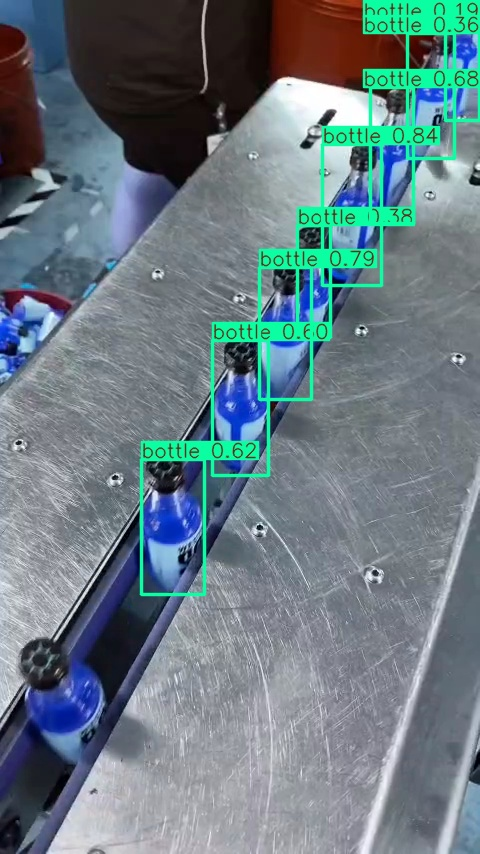

In [ ]:

# ============================================
# SMART REFRIGERATOR AI
# PHASE 3: IMPROVED BOTTLE DETECTION
# ============================================

# Import required libraries
import cv2
from ultralytics import YOLO
from IPython.display import display, Image

# Load the pretrained YOLOv8 model
model = YOLO("yolov8n.pt")

# Select GPU
device = 0 if torch.cuda.is_available() else "cpu"

# Open uploaded video
cap = cv2.VideoCapture(video_path)

# Initialize best detection results
best_count = 0
best_frame = None
best_result = None

# Check the first 30 frames at intervals of 5
for frame_number in range(0, 30, 5):

    # Move video reader to selected frame
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)

    # Read video frame
    success, frame = cap.read()

    # Stop if frame cannot be read
    if not success:
        break

    # Detect only bottle class (COCO class ID 39)
    results = model.predict(
        source=frame,
        device=device,
        imgsz = 640,
        conf=0.15,
        classes=[39],
        verbose=False
    )

    # Get current frame results
    result = results[0]

    # Count detected bottles
    count = len(result.boxes)

    # Save frame with highest bottle detections
    if count > best_count:
        best_count = count
        best_frame = frame.copy()
        best_result = result

# Release video
cap.release()

# Display detection results
print("Bottle Detection Completed")
print("Maximum bottles detected in sampled frames:", best_count)

# Display annotated frame
if best_result is not None:

    # Draw bounding boxes
    annotated_frame = best_result.plot()

    # Convert BGR to RGB
    annotated_frame = cv2.cvtColor(
        annotated_frame,
        cv2.COLOR_BGR2RGB
    )

    # Display image
    display(Image(data=cv2.imencode(
        ".jpg", annotated_frame
    )[1].tobytes()))

else:
    print("No bottles detected in the sampled frames.")
    print("The pretrained model may need bottle-specific training.")


requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 229ms
Prepared 1 package in 59ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Bottle Tracking Completed
Total Processed Frames: 382
Unique Tracking IDs: 43
Tracking IDs: [1, 2, 5, 9, 14, 15, 20, 21, 24, 25, 26, 33, 35, 36, 37, 38, 41, 50, 53, 63, 65, 67, 77, 78, 85, 86, 96, 98, 100, 103, 108, 109, 114, 119, 120, 124, 125, 130, 136, 138, 140, 146, 152]


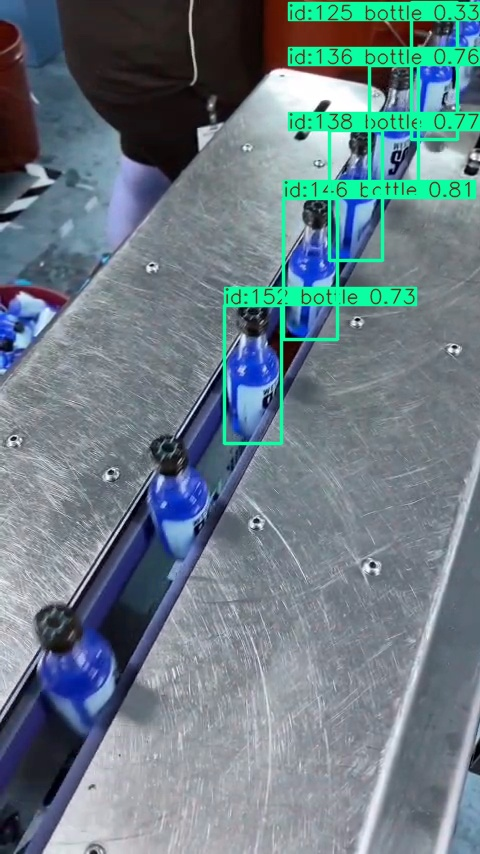

In [ ]:

# ============================================
# SMART REFRIGERATOR AI
# PHASE 4: BYTETRACK VISUALIZATION FIX
# ============================================

import cv2
from ultralytics import YOLO
from IPython.display import display, Image

# Load YOLO model
model = YOLO("yolov8n.pt")

# Select GPU
device = 0 if torch.cuda.is_available() else "cpu"

# Open uploaded video
cap = cv2.VideoCapture(video_path)

# Initialize tracking information
tracked_ids = set()
tracked_frames = 0
display_frame = None

# Process video frame by frame
while cap.isOpened():

    # Read next frame
    success, frame = cap.read()

    # Stop at video end
    if not success:
        break

    # Run YOLO and ByteTrack
    results = model.track(
        source=frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.15,
        classes=[39],
        device=device,
        verbose=False
    )

    # Get current result
    result = results[0]

    # Collect unique tracking IDs
    if result.boxes is not None and result.boxes.id is not None:
        ids = result.boxes.id.int().cpu().tolist()
        tracked_ids.update(ids)

    # Save an actual frame containing bottle detections
    if len(result.boxes) > 0:
        display_frame = result.plot()

    # Count processed frames
    tracked_frames += 1

# Release video
cap.release()

# Display tracking results
print("Bottle Tracking Completed")
print("Total Processed Frames:", tracked_frames)
print("Unique Tracking IDs:", len(tracked_ids))
print("Tracking IDs:", sorted(tracked_ids))

# Display detected bottle frame
if display_frame is not None:

    # Convert BGR to RGB
    display_frame = cv2.cvtColor(
        display_frame,
        cv2.COLOR_BGR2RGB
    )

    # Display actual tracking visualization
    display(Image(data=cv2.imencode(
        ".jpg", display_frame
    )[1].tobytes()))

else:
    print("No bottle detection found in any frame.")


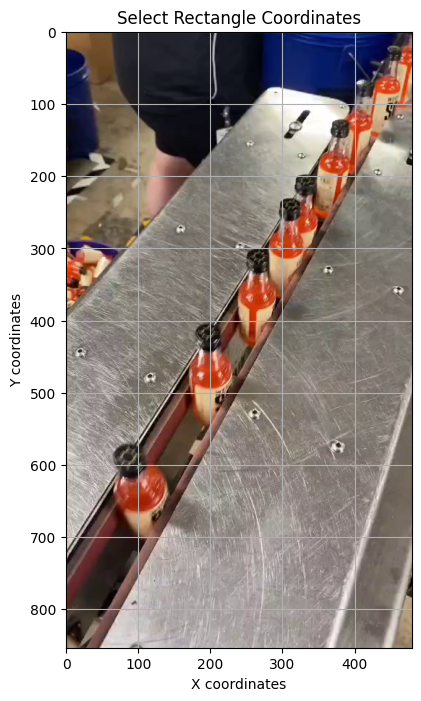

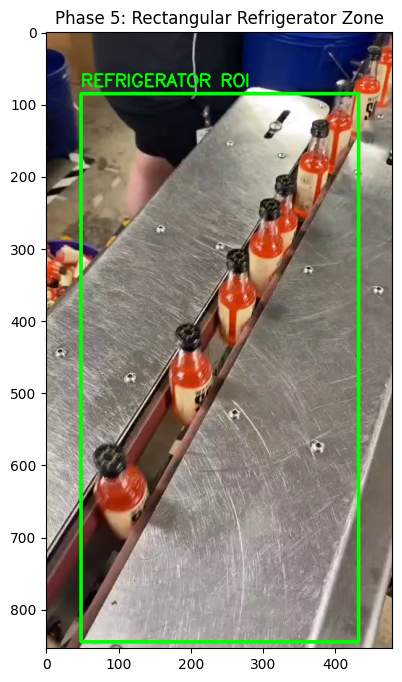

RECTANGULAR ROI CONFIGURATION COMPLETED
Left: 48
Top: 85
Right: 432
Bottom: 845


In [ ]:
# ============================================
# SMART REFRIGERATOR AI
# PHASE 5: RECTANGULAR ROI CONFIGURATION
# ============================================

import cv2
import matplotlib.pyplot as plt

# 1. Check that the video is available
if "video_path" not in globals():
    raise ValueError("Upload your video before running Phase 5.")

# 2. Open the uploaded video
cap = cv2.VideoCapture(video_path)

success, frame = cap.read()
cap.release()

if not success:
    raise ValueError("Unable to read the video.")

# 3. Display the first video frame with coordinates
rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(rgb_frame)
plt.title("Select Rectangle Coordinates")
plt.xlabel("X coordinates")
plt.ylabel("Y coordinates")
plt.grid()
plt.show()

# 4. Enter rectangle coordinates dynamically or statically
# Get actual frame size to scale safely
height, width = frame.shape[:2]

# Format: (left, top, right, bottom) scaled safely to fit the video
roi_x1 = int(width * 0.1)
roi_y1 = int(height * 0.1)
roi_x2 = int(width * 0.9)
roi_y2 = int(height * 0.99)

# 5. Validate rectangle coordinates
if not (
    0 <= roi_x1 < roi_x2 <= width
    and 0 <= roi_y1 < roi_y2 <= height
):
    raise ValueError(f"Invalid rectangle coordinates for frame size {width}x{height}.")

# 6. Draw the rectangular refrigerator zone
roi_frame = frame.copy()

cv2.rectangle(
    roi_frame,
    (roi_x1, roi_y1),
    (roi_x2, roi_y2),
    (0, 255, 0),
    3
)

cv2.putText(
    roi_frame,
    "REFRIGERATOR ROI",
    (roi_x1, max(30, roi_y1 - 10)),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    (0, 255, 0),
    2
)

# 7. Display the configured rectangle
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(roi_frame, cv2.COLOR_BGR2RGB))
plt.title("Phase 5: Rectangular Refrigerator Zone")
plt.axis("on")
plt.show()

# 8. Save ROI coordinates for Phase 6
print("RECTANGULAR ROI CONFIGURATION COMPLETED")
print("Left:", roi_x1)
print("Top:", roi_y1)
print("Right:", roi_x2)
print("Bottom:", roi_y2)

RECTANGULAR ROI
Left: 48
Top: 85
Right: 432
Bottom: 845
RECTANGULAR ROI BOTTLE COUNTING COMPLETED
------------------------------------------
Total Processed Frames: 382
Unique Tracking IDs: 43
Total Entries: 16
Total Exits: 0
Net Inventory Change: 16

BOTTLE CROSSING HISTORY:


,Frame,Tracking_ID,Event,Quantity_Change
0,5,9,ENTRY,1
1,20,20,ENTRY,1
2,33,21,ENTRY,1
3,50,25,ENTRY,1
4,67,24,ENTRY,1
5,81,26,ENTRY,1
6,97,33,ENTRY,1
7,114,36,ENTRY,1
8,127,35,ENTRY,1
9,143,37,ENTRY,1


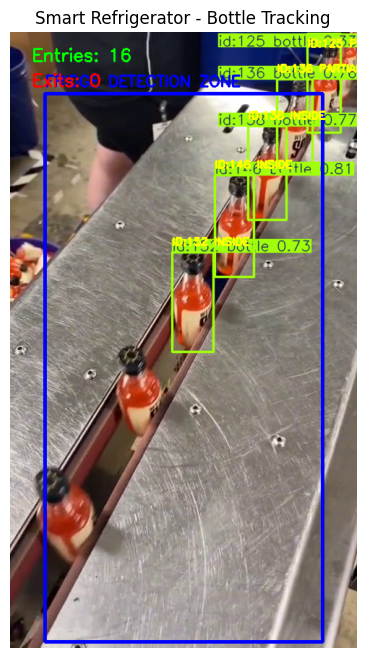

In [ ]:

'''# ============================================
# SMART REFRIGERATOR AI
# PHASE 6: DIRECTIONAL BOTTLE COUNTING
# IMPROVED RECTANGULAR ROI VERSION
# ============================================

import cv2
import torch
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ============================================
# 1. LOAD YOLO MODEL
# ============================================

model = YOLO("yolov8n.pt")

# Select GPU if available
device = 0 if torch.cuda.is_available() else "cpu"

# ============================================
# 2. ROI SETTINGS
# ============================================

# Check Phase 5 ROI variables
if not all(name in globals() for name in
           ["roi_x1", "roi_y1", "roi_x2", "roi_y2"]):
    raise ValueError("Run Phase 5 first. ROI coordinates not found.")

# Read rectangular ROI coordinates
ROI_X1 = int(roi_x1)
ROI_Y1 = int(roi_y1)
ROI_X2 = int(roi_x2)
ROI_Y2 = int(roi_y2)

# Counting configuration
CONFIRM_FRAMES = 1
MAX_FRAME_GAP = 6

print("RECTANGULAR ROI")
print("Left:", ROI_X1)
print("Top:", ROI_Y1)
print("Right:", ROI_X2)
print("Bottom:", ROI_Y2)

# ============================================
# 3. INITIALIZE TRACKING VARIABLES
# ============================================

# Store information for every tracking ID
previous_positions = {}

# Store unique tracking IDs
tracking_ids = set()

# Store confirmed bottle events
crossing_events = []

entry_count = 0
exit_count = 0

# Open uploaded video
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError("Could not open uploaded video.")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# ============================================
# 4. ROI STATUS FUNCTION
# ============================================

def get_roi_status(box):

    x_min, y_min, x_max, y_max = map(int, box)

    # Completely inside the rectangular ROI
    if (
        x_min >= ROI_X1 and
        y_min >= ROI_Y1 and
        x_max <= ROI_X2 and
        y_max <= ROI_Y2
    ):
        return "INSIDE"

    # Completely outside the rectangular ROI
    if (
        x_max < ROI_X1 or
        x_min > ROI_X2 or
        y_max < ROI_Y1 or
        y_min > ROI_Y2
    ):
        return "OUTSIDE"

    # Partially overlapping the ROI
    return "PARTIAL"


# ============================================
# 5. CALCULATE ROI OVERLAP RATIO
# ============================================

def get_overlap_ratio(box):

    x_min, y_min, x_max, y_max = map(float, box)

    # Calculate bottle bounding box area
    box_area = max(0, x_max - x_min) * max(0, y_max - y_min)

    if box_area == 0:
        return 0.0

    # Calculate intersection with rectangular ROI
    ix1 = max(x_min, ROI_X1)
    iy1 = max(y_min, ROI_Y1)
    ix2 = min(x_max, ROI_X2)
    iy2 = min(y_max, ROI_Y2)

    intersection = (
        max(0, ix2 - ix1) *
        max(0, iy2 - iy1)
    )

    return intersection / box_area


# ============================================
# 6. VIDEO PROCESSING
# ============================================

frame_number = 0
last_annotated_frame = None

while cap.isOpened():

    success, frame = cap.read()

    if not success:
        break

    # YOLO detection and ByteTrack tracking
    results = model.track(
        source=frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.15,
        classes=[39],
        device=device,
        verbose=False
    )

    result = results[0]

    # Create annotated frame
    annotated_frame = result.plot()

    # Draw rectangular ROI
    cv2.rectangle(
        annotated_frame,
        (ROI_X1, ROI_Y1),
        (ROI_X2, ROI_Y2),
        (255, 0, 0),
        3

    )

    cv2.putText(
        annotated_frame,
        "FRIDGE DETECTION ZONE",
        (ROI_X1, max(25, ROI_Y1 - 10)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 0, 0),
        2
    )

    # ========================================
    # 7. PROCESS DETECTED BOTTLES
    # ========================================

    if result.boxes is not None and result.boxes.id is not None:

        ids = result.boxes.id.int().cpu().tolist()
        boxes = result.boxes.xyxy.cpu().tolist()

        for track_id, box in zip(ids, boxes):

            tracking_ids.add(track_id)

            # Determine current bottle position
            current_status = get_roi_status(box)

            # Calculate overlap ratio
            current_overlap = get_overlap_ratio(box)

            # --------------------------------
            # INITIALIZE NEW TRACKING ID
            # --------------------------------

            if track_id not in previous_positions:

                # Known initial position
                if current_status in ["OUTSIDE", "INSIDE"]:
                    initial_anchor = current_status
                else:
                    # First detected as partial:
                    # Wait for movement to determine direction
                    initial_anchor = None

                previous_positions[track_id] = {
                    "anchor_status": initial_anchor,
                    "candidate": None,
                    "candidate_frames": 0,
                    "last_frame": frame_number,
                    "last_overlap": current_overlap,
                    "overlap_direction": 0
                }

                continue

            # Retrieve tracking history
            history = previous_positions[track_id]

            # --------------------------------
            # CHECK TRACKING GAP
            # --------------------------------

            frame_gap = frame_number - history["last_frame"]

            if frame_gap > MAX_FRAME_GAP:

                history["candidate"] = None
                history["candidate_frames"] = 0

                history["last_frame"] = frame_number
                history["last_overlap"] = current_overlap

                continue

            # --------------------------------
            # TRACK OVERLAP DIRECTION
            # --------------------------------

            overlap_change = (
                current_overlap - history["last_overlap"]
            )

            # Positive = moving into ROI
            # Negative = moving out of ROI
            if overlap_change > 0.01:
                history["overlap_direction"] += 1

            elif overlap_change < -0.01:
                history["overlap_direction"] -= 1

            history["last_overlap"] = current_overlap

            # --------------------------------
            # CONFIRM TRANSITION
            # --------------------------------

            anchor = history["anchor_status"]

            if current_status == "PARTIAL":

                # Partial overlap is not a confirmed crossing
                history["candidate"] = None
                history["candidate_frames"] = 0

            else:

                # First observed position was PARTIAL
                if anchor is None:

                    if history["candidate"] == current_status:
                        history["candidate_frames"] += 1
                    else:
                        history["candidate"] = current_status
                        history["candidate_frames"] = 1

                    if history["candidate_frames"] >= CONFIRM_FRAMES:

                        direction = history["overlap_direction"]

                        # Partial to complete inside:
                        # Confirm entry when overlap increased
                        if (
                            current_status == "INSIDE"
                            and direction > 0
                        ):

                            entry_count += 1

                            crossing_events.append({
                                "Frame": frame_number,
                                "Tracking_ID": track_id,
                                "Event": "ENTRY",
                                "Quantity_Change": 1
                            })

                            history["anchor_status"] = "INSIDE"

                        # Partial to complete outside:
                        # Confirm exit when overlap decreased
                        elif (
                            current_status == "OUTSIDE"
                            and direction < 0
                        ):

                            exit_count += 1

                            crossing_events.append({
                                "Frame": frame_number,
                                "Tracking_ID": track_id,
                                "Event": "EXIT",
                                "Quantity_Change": -1
                            })

                            history["anchor_status"] = "OUTSIDE"

                        else:
                            # Establish current position without
                            # generating an uncertain event
                            history["anchor_status"] = current_status

                        history["candidate"] = None
                        history["candidate_frames"] = 0

                # Normal known-position tracking
                elif current_status == anchor:

                    # Bottle returned to its previous position
                    history["candidate"] = None
                    history["candidate_frames"] = 0

                else:

                    # Confirm the opposite endpoint
                    if history["candidate"] == current_status:
                        history["candidate_frames"] += 1
                    else:
                        history["candidate"] = current_status
                        history["candidate_frames"] = 1

                    if history["candidate_frames"] >= CONFIRM_FRAMES:

                        # OUTSIDE to INSIDE = ENTRY
                        if (
                            anchor == "OUTSIDE"
                            and current_status == "INSIDE"
                        ):

                            entry_count += 1
                            event_type = "ENTRY"
                            quantity_change = 1

                        # INSIDE to OUTSIDE = EXIT
                        elif (
                            anchor == "INSIDE"
                            and current_status == "OUTSIDE"
                        ):

                            exit_count += 1
                            event_type = "EXIT"
                            quantity_change = -1

                        else:
                            event_type = None
                            quantity_change = 0

                        # Save confirmed event
                        if event_type is not None:

                            crossing_events.append({
                                "Frame": frame_number,
                                "Tracking_ID": track_id,
                                "Event": event_type,
                                "Quantity_Change": quantity_change
                            })

                        # Update confirmed position
                        history["anchor_status"] = current_status
                        history["candidate"] = None
                        history["candidate_frames"] = 0

            # Update last processed frame
            history["last_frame"] = frame_number

            # --------------------------------
            # DISPLAY TRACKING INFORMATION
            # --------------------------------

            x_min, y_min, x_max, y_max = map(int, box)

            cv2.putText(
                annotated_frame,
                f"ID:{track_id} {current_status}",
                (x_min, max(20, y_min - 10)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 255),
                2
            )

    # ========================================
    # 8. DISPLAY LIVE COUNTERS
    # ========================================

    cv2.putText(
        annotated_frame,
        f"Entries: {entry_count}",
        (30, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

    cv2.putText(
        annotated_frame,
        f"Exits: {exit_count}",
        (30, 75),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 0, 255),
        2
    )

    last_annotated_frame = annotated_frame

    frame_number += 1


# ============================================
# 9. RELEASE VIDEO
# ============================================

cap.release()

# ============================================
# 10. CREATE EVENT HISTORY
# ============================================

events_df = pd.DataFrame(
    crossing_events,
    columns=[
        "Frame",
        "Tracking_ID",
        "Event",
        "Quantity_Change"
    ]
)

# ============================================
# 11. DISPLAY FINAL RESULTS
# ============================================

print("RECTANGULAR ROI BOTTLE COUNTING COMPLETED")
print("------------------------------------------")

print("Total Processed Frames:", frame_number)
print("Unique Tracking IDs:", len(tracking_ids))
print("Total Entries:", entry_count)
print("Total Exits:", exit_count)
print("Net Inventory Change:", entry_count - exit_count)

print("\nBOTTLE CROSSING HISTORY:")

display(events_df)

# ============================================
# 12. DISPLAY FINAL ANNOTATED FRAME
# ============================================

if last_annotated_frame is not None:

    rgb_result = cv2.cvtColor(
        last_annotated_frame,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(14, 8))
    plt.imshow(rgb_result)
    plt.title("Smart Refrigerator - Bottle Tracking")
    plt.axis("off")
    plt.show()

else:
    print("No video frames were processed.")'''


RECTANGULAR ROI
Left: 48
Top: 85
Right: 432
Bottom: 845
ENTRY | ID: 21 | Frame: 18 | Inventory: +1
ENTRY | ID: 24 | Frame: 48 | Inventory: +1
ENTRY | ID: 26 | Frame: 63 | Inventory: +1
ENTRY | ID: 35 | Frame: 109 | Inventory: +1
ENTRY | ID: 37 | Frame: 134 | Inventory: +1
ENTRY | ID: 38 | Frame: 142 | Inventory: +1
ENTRY | ID: 86 | Frame: 213 | Inventory: +1
EXIT | ID: 67 | Frame: 222 | Inventory: -1
ENTRY | ID: 96 | Frame: 228 | Inventory: +1
ENTRY | ID: 98 | Frame: 251 | Inventory: +1
EXIT | ID: 98 | Frame: 292 | Inventory: -1
EXIT | ID: 86 | Frame: 306 | Inventory: -1
EXIT | ID: 63 | Frame: 318 | Inventory: -1
EXIT | ID: 103 | Frame: 332 | Inventory: -1
EXIT | ID: 124 | Frame: 367 | Inventory: -1
EXIT | ID: 125 | Frame: 377 | Inventory: -1

RECTANGULAR ROI BOTTLE COUNTING COMPLETED
------------------------------------------
Total Processed Frames: 382
Unique Tracking IDs: 43
Total Entries: 9
Total Exits: 7
Net Inventory Change: 2

BOTTLE CROSSING HISTORY:


,Frame,Tracking_ID,Event,Quantity_Change
0,18,21,ENTRY,1
1,48,24,ENTRY,1
2,63,26,ENTRY,1
3,109,35,ENTRY,1
4,134,37,ENTRY,1
5,142,38,ENTRY,1
6,213,86,ENTRY,1
7,222,67,EXIT,-1
8,228,96,ENTRY,1
9,251,98,ENTRY,1


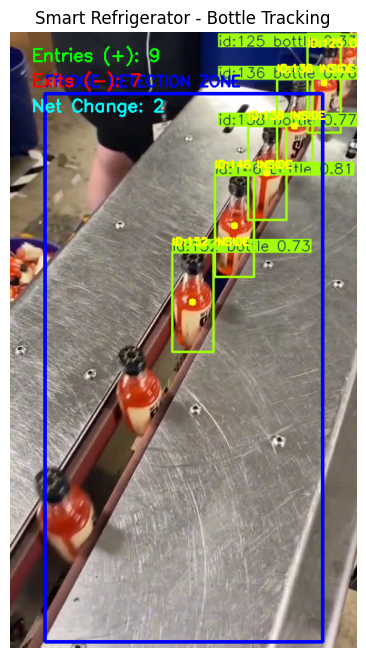

In [ ]:

# ============================================
# SMART REFRIGERATOR AI
# PHASE 6: DIRECTIONAL BOTTLE COUNTING
# RECTANGULAR ROI - CENTER POINT VERSION
# ============================================

import cv2
import torch
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ============================================
# 1. LOAD YOLO MODEL
# ============================================

model = YOLO("yolov8n.pt")

# Select GPU if available
device = 0 if torch.cuda.is_available() else "cpu"

# ============================================
# 2. ROI SETTINGS
# ============================================

# Check whether Phase 5 ROI coordinates exist
if not all(name in globals() for name in
           ["roi_x1", "roi_y1", "roi_x2", "roi_y2"]):
    raise ValueError("Run Phase 5 first. ROI coordinates not found.")

# Read rectangular ROI coordinates
ROI_X1 = int(roi_x1)
ROI_Y1 = int(roi_y1)
ROI_X2 = int(roi_x2)
ROI_Y2 = int(roi_y2)

# Validate ROI coordinates
if ROI_X1 >= ROI_X2 or ROI_Y1 >= ROI_Y2:
    raise ValueError("Invalid ROI coordinates. Check Phase 5.")

# Counting configuration
MAX_FRAME_GAP = 30

print("RECTANGULAR ROI")
print("Left:", ROI_X1)
print("Top:", ROI_Y1)
print("Right:", ROI_X2)
print("Bottom:", ROI_Y2)

# ============================================
# 3. INITIALIZE TRACKING VARIABLES
# ============================================

# Store the last confirmed position of each bottle
previous_positions = {}

# Store unique tracking IDs
tracking_ids = set()

# Store bottle crossing events
crossing_events = []

# Initialize counters
entry_count = 0
exit_count = 0

# Open uploaded video
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError("Could not open uploaded video.")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# ============================================
# 4. CENTER POINT ROI STATUS FUNCTION
# ============================================

def get_roi_status(box):

    x_min, y_min, x_max, y_max = map(float, box)

    # Calculate bottle bounding box center
    center_x = (x_min + x_max) / 2
    center_y = (y_min + y_max) / 2

    # Check whether center is inside rectangle
    if (
        ROI_X1 <= center_x <= ROI_X2 and
        ROI_Y1 <= center_y <= ROI_Y2
    ):
        return "INSIDE"

    return "OUTSIDE"


# ============================================
# 5. VIDEO PROCESSING
# ============================================

frame_number = 0
last_annotated_frame = None

while cap.isOpened():

    success, frame = cap.read()

    if not success:
        break

    # YOLO detection and ByteTrack tracking
    results = model.track(
        source=frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.15,
        classes=[39],
        device=device,
        verbose=False
    )

    result = results[0]

    # Create annotated frame
    annotated_frame = result.plot()

    # Draw rectangular ROI
    cv2.rectangle(
        annotated_frame,
        (ROI_X1, ROI_Y1),
        (ROI_X2, ROI_Y2),
        (255, 0, 0),
        3
    )

    cv2.putText(
        annotated_frame,
        "FRIDGE DETECTION ZONE",
        (ROI_X1, max(25, ROI_Y1 - 10)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 0, 0),
        2
    )

    # ========================================
    # 6. PROCESS DETECTED BOTTLES
    # ========================================

    if (
        result.boxes is not None
        and result.boxes.id is not None
    ):

        # Get tracking IDs and bounding boxes
        ids = result.boxes.id.int().cpu().tolist()
        boxes = result.boxes.xyxy.cpu().tolist()

        for track_id, box in zip(ids, boxes):

            tracking_ids.add(track_id)

            # Calculate bottle center
            x_min, y_min, x_max, y_max = map(int, box)

            center_x = int((x_min + x_max) / 2)
            center_y = int((y_min + y_max) / 2)

            # Determine current ROI position
            current_status = get_roi_status(box)

            # --------------------------------
            # INITIALIZE NEW TRACKING ID
            # --------------------------------

            if track_id not in previous_positions:

                # Save initial position.
                # Initially inside bottles are baseline inventory.
                previous_positions[track_id] = {
                    "anchor_status": current_status,
                    "last_frame": frame_number
                }

                continue

            # --------------------------------
            # RETRIEVE TRACKING HISTORY
            # --------------------------------

            history = previous_positions[track_id]

            anchor = history["anchor_status"]

            frame_gap = frame_number - history["last_frame"]

            # --------------------------------
            # CHECK TRACKING GAP
            # --------------------------------

            if frame_gap > MAX_FRAME_GAP:

                # Avoid counting an uncertain transition
                history["anchor_status"] = current_status
                history["last_frame"] = frame_number

                continue

            # --------------------------------
            # DIRECTIONAL COUNTING
            # --------------------------------

            # OUTSIDE -> INSIDE = ENTRY (+1)
            if (
                anchor == "OUTSIDE"
                and current_status == "INSIDE"
            ):

                entry_count += 1

                crossing_events.append({
                    "Frame": frame_number,
                    "Tracking_ID": track_id,
                    "Event": "ENTRY",
                    "Quantity_Change": 1
                })

                print(
                    f"ENTRY | ID: {track_id} | "
                    f"Frame: {frame_number} | "
                    f"Inventory: +1"
                )

            # INSIDE -> OUTSIDE = EXIT (-1)
            elif (
                anchor == "INSIDE"
                and current_status == "OUTSIDE"
            ):

                exit_count += 1

                crossing_events.append({
                    "Frame": frame_number,
                    "Tracking_ID": track_id,
                    "Event": "EXIT",
                    "Quantity_Change": -1
                })

                print(
                    f"EXIT | ID: {track_id} | "
                    f"Frame: {frame_number} | "
                    f"Inventory: -1"
                )

            # --------------------------------
            # UPDATE TRACKING HISTORY
            # --------------------------------

            # Update only after checking the transition
            history["anchor_status"] = current_status
            history["last_frame"] = frame_number

            # --------------------------------
            # DISPLAY BOTTLE CENTER AND STATUS
            # --------------------------------

            # Draw center point
            cv2.circle(
                annotated_frame,
                (center_x, center_y),
                5,
                (0, 255, 255),
                -1
            )

            # Display tracking ID and position
            cv2.putText(
                annotated_frame,
                f"ID:{track_id} {current_status}",
                (x_min, max(20, y_min - 10)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 255),
                2
            )

    # ========================================
    # 7. DISPLAY LIVE COUNTERS
    # ========================================

    net_inventory_change = entry_count - exit_count

    cv2.putText(
        annotated_frame,
        f"Entries (+): {entry_count}",
        (30, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

    cv2.putText(
        annotated_frame,
        f"Exits (-): {exit_count}",
        (30, 75),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 0, 255),
        2
    )

    cv2.putText(
        annotated_frame,
        f"Net Change: {net_inventory_change}",
        (30, 110),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (255, 255, 0),
        2
    )

    last_annotated_frame = annotated_frame

    frame_number += 1


# ============================================
# 8. RELEASE VIDEO
# ============================================

cap.release()

# ============================================
# 9. CREATE EVENT HISTORY
# ============================================

events_df = pd.DataFrame(
    crossing_events,
    columns=[
        "Frame",
        "Tracking_ID",
        "Event",
        "Quantity_Change"
    ]
)

# ============================================
# 10. DISPLAY FINAL RESULTS
# ============================================

net_inventory_change = entry_count - exit_count

print("\nRECTANGULAR ROI BOTTLE COUNTING COMPLETED")
print("------------------------------------------")

print("Total Processed Frames:", frame_number)
print("Unique Tracking IDs:", len(tracking_ids))
print("Total Entries:", entry_count)
print("Total Exits:", exit_count)
print("Net Inventory Change:", net_inventory_change)

print("\nBOTTLE CROSSING HISTORY:")

display(events_df)

# ============================================
# 11. DISPLAY FINAL ANNOTATED FRAME
# ============================================

if last_annotated_frame is not None:

    rgb_result = cv2.cvtColor(
        last_annotated_frame,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(14, 8))
    plt.imshow(rgb_result)
    plt.title("Smart Refrigerator - Bottle Tracking")
    plt.axis("off")
    plt.show()

else:
    print("No video frames were processed.")



In [ ]:

# ==========================================
# PHASE 7: DYNAMIC BOTTLE INVENTORY MANAGEMENT
# ==========================================

import pandas as pd

# 1. Ask the user to enter the initial bottle inventory.
starting_inventory = int(input("Enter starting bottle inventory: "))

# 2. Validate the starting inventory.
if starting_inventory < 0:
    raise ValueError("Starting inventory cannot be negative.")

# 3. Check that Phase 6 generated the required event data.
required_columns = ["Frame", "Tracking_ID", "Event", "Quantity_Change"]

if not all(column in events_df.columns for column in required_columns):
    raise ValueError("Phase 6 events_df is missing required columns.")

# 4. Initialize the current inventory.
current_inventory = starting_inventory

# 5. Create a list to store inventory transaction history.
inventory_history = []

# 6. Process every entry and exit event from Phase 6.
for _, event in events_df.iterrows():

    # Read the event information.
    frame = event["Frame"]
    tracking_id = event["Tracking_ID"]
    event_type = str(event["Event"]).strip().upper()

    # Save inventory before the transaction.
    inventory_before = current_inventory

    # Increase inventory when a bottle enters.
    if event_type == "ENTRY":
        current_inventory += 1

    # Decrease inventory when a bottle exits.
    elif event_type == "EXIT":
        if current_inventory > 0:
            current_inventory -= 1
        else:
            print(f"Warning: Inventory is already zero at frame {frame}.")

    # Reject unexpected event labels.
    else:
        print(f"Unknown event '{event_type}' at frame {frame}.")
        continue

    # Store the updated inventory transaction.
    inventory_history.append({
        "Frame": frame,
        "Tracking_ID": tracking_id,
        "Event": event_type,
        "Inventory_Before": inventory_before,
        "Inventory_After": current_inventory
    })

# 7. Convert transaction history into a DataFrame.
inventory_history_df = pd.DataFrame(
    inventory_history,
    columns=[
        "Frame",
        "Tracking_ID",
        "Event",
        "Inventory_Before",
        "Inventory_After"
    ]
)

# 8. Calculate total inventory changes.
total_entries = sum(
    1 for event in inventory_history if event["Event"] == "ENTRY"
)

total_exits = sum(
    1 for event in inventory_history if event["Event"] == "EXIT"
)

# 9. Display the final inventory report.
print("\n========== PHASE 7: INVENTORY REPORT ==========")

print("Starting Inventory:", starting_inventory)
print("Total Entries:", total_entries)
print("Total Exits:", total_exits)
print("Net Inventory Change:", current_inventory - starting_inventory)
print("Final Inventory:", current_inventory)

# 10. Display transaction history.
print("\n========== INVENTORY TRANSACTION HISTORY ==========")

if not inventory_history_df.empty:
    display(inventory_history_df)
else:
    print("No bottle entry or exit events detected.")

print("\nPHASE 7 INVENTORY MANAGEMENT COMPLETED!")


Enter starting bottle inventory: 0

========== PHASE 7: INVENTORY REPORT ==========
Starting Inventory: 0
Total Entries: 9
Total Exits: 7
Net Inventory Change: 2
Final Inventory: 2

========== INVENTORY TRANSACTION HISTORY ==========


,Frame,Tracking_ID,Event,Inventory_Before,Inventory_After
0,18,21,ENTRY,0,1
1,48,24,ENTRY,1,2
2,63,26,ENTRY,2,3
3,109,35,ENTRY,3,4
4,134,37,ENTRY,4,5
5,142,38,ENTRY,5,6
6,213,86,ENTRY,6,7
7,222,67,EXIT,7,6
8,228,96,ENTRY,6,7
9,251,98,ENTRY,7,8



PHASE 7 INVENTORY MANAGEMENT COMPLETED!


In [ ]:

# ==========================================================
# SMART REFRIGERATOR AI
# PHASE 8: VIDEO PLAYBACK AND INVENTORY VISUALIZATION
# RECTANGULAR ROI VERSION
# ==========================================================

import cv2
import os
import torch
import pandas as pd
import subprocess

from ultralytics import YOLO
from google.colab import files
from IPython.display import display, Video

# ----------------------------------------------------------
# 1. CHECK REQUIRED VARIABLES FROM PREVIOUS PHASES
# ----------------------------------------------------------

required_variables = [
    "roi_x1",
    "roi_y1",
    "roi_x2",
    "roi_y2",
    "events_df",
    "inventory_history_df",
    "starting_inventory"
]

for variable in required_variables:

    if variable not in globals():

        raise ValueError(
            f"Missing {variable}. Run previous phases first."
        )

# ----------------------------------------------------------
# 2. GET RECTANGULAR ROI COORDINATES
# ----------------------------------------------------------

ROI_X1 = int(roi_x1)
ROI_Y1 = int(roi_y1)
ROI_X2 = int(roi_x2)
ROI_Y2 = int(roi_y2)

# ----------------------------------------------------------
# 3. UPLOAD THE SAME VIDEO USED IN PHASE 6
# ----------------------------------------------------------

print("Upload the SAME video used in Phase 6.")

uploaded_video = files.upload()

if not uploaded_video:

    raise ValueError(
        "No video uploaded."
    )

phase8_video_path = list(uploaded_video.keys())[0]

# ----------------------------------------------------------
# 4. LOAD YOLO MODEL
# ----------------------------------------------------------

phase8_model = YOLO("yolov8n.pt")

device = 0 if torch.cuda.is_available() else "cpu"

# ----------------------------------------------------------
# 5. PREPARE VIDEO READER AND WRITER
# ----------------------------------------------------------

cap = cv2.VideoCapture(phase8_video_path)

if not cap.isOpened():

    raise ValueError("Unable to open uploaded video.")

fps = cap.get(cv2.CAP_PROP_FPS)

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

if fps <= 0:
    fps = 25

# Validate ROI against uploaded video dimensions
if not (
    0 <= ROI_X1 < ROI_X2 <= width
    and 0 <= ROI_Y1 < ROI_Y2 <= height
):

    cap.release()

    raise ValueError(
        "ROI coordinates do not match video dimensions. "
        "Upload the same video used in Phase 5 and Phase 6."
    )

output_path = "/content/phase8_inventory_playback.mp4"

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

writer = cv2.VideoWriter(
    output_path,
    fourcc,
    fps,
    (width, height)
)

if not writer.isOpened():

    cap.release()

    raise ValueError("Unable to create output video.")

# ----------------------------------------------------------
# 6. PREPARE PHASE 6 EVENT DATA
# ----------------------------------------------------------

# Group events by video frame
events_by_frame = {}

for _, event in events_df.iterrows():

    frame = int(event["Frame"])

    if frame not in events_by_frame:

        events_by_frame[frame] = []

    events_by_frame[frame].append(event)

# ----------------------------------------------------------
# 7. PREPARE PHASE 7 INVENTORY HISTORY
# ----------------------------------------------------------

# Sort transactions by video frame
sorted_history = inventory_history_df.sort_values(
    by="Frame"
)

# Store the final inventory value for each frame
inventory_by_frame = {}

for _, transaction in sorted_history.iterrows():

    frame = int(transaction["Frame"])

    inventory_by_frame[frame] = int(
        transaction["Inventory_After"]
    )

# Initialize inventory
current_inventory = starting_inventory

# Initialize event counters
total_entries = 0
total_exits = 0

# ----------------------------------------------------------
# 8. PROCESS VIDEO FRAME BY FRAME
# ----------------------------------------------------------

frame_number = 0

print("Processing video with Rectangular ROI...")

while cap.isOpened():

    success, frame = cap.read()

    if not success:
        break

    # --------------------------------------
    # YOLO DETECTION AND BYTE TRACKING
    # --------------------------------------

    results = phase8_model.track(
        source=frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.15,
        classes=[39],
        device=device,
        verbose=False
    )

    result = results[0]

    # Draw bottle bounding boxes and tracking IDs
    annotated_frame = result.plot()

    # --------------------------------------
    # DRAW RECTANGULAR ROI
    # --------------------------------------

    cv2.rectangle(
        annotated_frame,
        (ROI_X1, ROI_Y1),
        (ROI_X2, ROI_Y2),
        (255, 0, 0),
        3
    )

    cv2.putText(
        annotated_frame,
        "FRIDGE DETECTION ZONE",
        (ROI_X1, max(25, ROI_Y1 - 10)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 0, 0),
        2
    )

    # --------------------------------------
    # UPDATE INVENTORY FROM PHASE 7
    # --------------------------------------

    if frame_number in inventory_by_frame:

        current_inventory = inventory_by_frame[
            frame_number
        ]

    # --------------------------------------
    # DISPLAY CONFIRMED PHASE 6 EVENTS
    # --------------------------------------

    frame_events = events_by_frame.get(
        frame_number,
        []
    )

    for index, event in enumerate(frame_events):

        event_type = str(
            event["Event"]
        ).strip().upper()

        tracking_id = int(
            event["Tracking_ID"]
        )

        if event_type == "ENTRY":

            total_entries += 1

            event_color = (0, 255, 0)

            event_text = (
                f"ENTRY +1 | ID: {tracking_id}"
            )

        elif event_type == "EXIT":

            total_exits += 1

            event_color = (0, 0, 255)

            event_text = (
                f"EXIT -1 | ID: {tracking_id}"
            )

        else:

            continue

        cv2.putText(
            annotated_frame,
            event_text,
            (20, 145 + index * 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            event_color,
            2
        )

    # --------------------------------------
    # DISPLAY INVENTORY INFORMATION
    # --------------------------------------

    cv2.putText(
        annotated_frame,
        f"INVENTORY: {current_inventory}",
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 255, 255),
        3
    )

    cv2.putText(
        annotated_frame,
        f"ENTRIES: +{total_entries}",
        (20, 80),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

    cv2.putText(
        annotated_frame,
        f"EXITS: -{total_exits}",
        (20, 115),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 0, 255),
        2
    )

    # --------------------------------------
    # SAVE ANNOTATED VIDEO FRAME
    # --------------------------------------

    writer.write(annotated_frame)

    frame_number += 1

# ----------------------------------------------------------
# 9. RELEASE VIDEO RESOURCES
# ----------------------------------------------------------

cap.release()

writer.release()

# ----------------------------------------------------------
# 10. CONVERT VIDEO TO BROWSER-FRIENDLY FORMAT
# ----------------------------------------------------------

browser_video_path = (
    "/content/phase8_inventory_playback_h264.mp4"
)

conversion = subprocess.run(
    [
        "ffmpeg",
        "-y",
        "-i",
        output_path,
        "-vcodec",
        "libx264",
        "-pix_fmt",
        "yuv420p",
        "-acodec",
        "aac",
        browser_video_path
    ],
    capture_output=True,
    text=True
)

if conversion.returncode == 0:

    output_path = browser_video_path

else:

    print("Using original MP4 video format.")

# ----------------------------------------------------------
# 11. DISPLAY FINAL INVENTORY REPORT
# ----------------------------------------------------------

print("\n========================================")
print("PHASE 8: INVENTORY VISUALIZATION REPORT")
print("========================================")

print("Processed Frames:", frame_number)

print("Total Entries:", total_entries)

print("Total Exits:", total_exits)

print("Starting Inventory:", starting_inventory)

print("Final Inventory:", current_inventory)

print(
    "Net Inventory Change:",
    current_inventory - starting_inventory
)

# ----------------------------------------------------------
# 12. PLAY PROCESSED VIDEO IN GOOGLE COLAB
# ----------------------------------------------------------

print("\n========================================")
print("PROCESSED VIDEO PLAYBACK")
print("========================================")

display(
    Video(
        output_path,
        embed=True,
        width=900
    )
)

print("\nPHASE 8 VIDEO PLAYBACK COMPLETED!")


Upload the SAME video used in Phase 6.


Saving WhatsApp Video 2026-11-11 at 1.31.20 PM.mp4 to WhatsApp Video 2026-11-11 at 1.31.20 PM.mp4
Processing video with Rectangular ROI...

PHASE 8: INVENTORY VISUALIZATION REPORT
Processed Frames: 382
Total Entries: 9
Total Exits: 7
Starting Inventory: 0
Final Inventory: 2
Net Inventory Change: 2

PROCESSED VIDEO PLAYBACK



PHASE 8 VIDEO PLAYBACK COMPLETED!


In [ ]:
from google.colab import files
files.download("/content/phase8_inventory_playback_h264.mp4")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ==========================================
# PHASE 8: DATABASE HISTORY MANAGEMENT
# ==========================================

import sqlite3
import pandas as pd
from datetime import datetime

# 1. Create or connect to the SQLite database.
database_path = "/content/bottle_inventory.db"

connection = sqlite3.connect(database_path)

# 2. Create a table for bottle inventory transactions.
cursor = connection.cursor()

cursor.execute("""
CREATE TABLE IF NOT EXISTS bottle_events (

    Transaction_ID INTEGER PRIMARY KEY AUTOINCREMENT,

    Frame INTEGER,

    Tracking_ID INTEGER,

    Event TEXT,

    Inventory_Before INTEGER,

    Inventory_After INTEGER,

    Event_Time TEXT,

    UNIQUE(Frame, Tracking_ID, Event)
)
""")

# 3. Save Phase 7 inventory history into the database.
recorded_time = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

if not inventory_history_df.empty:

    for _, record in inventory_history_df.iterrows():

        cursor.execute("""
        INSERT OR IGNORE INTO bottle_events
        (
            Frame,
            Tracking_ID,
            Event,
            Inventory_Before,
            Inventory_After,
            Event_Time
        )
        VALUES (?, ?, ?, ?, ?, ?)
        """, (
            int(record["Frame"]),
            int(record["Tracking_ID"]),
            str(record["Event"]),
            int(record["Inventory_Before"]),
            int(record["Inventory_After"]),
            recorded_time
        ))

# 4. Commit database changes.
connection.commit()

# 5. Retrieve all stored bottle transactions.
history_df = pd.read_sql_query(
    "SELECT * FROM bottle_events ORDER BY Transaction_ID",
    connection
)

# 6. Calculate database statistics.
total_transactions = len(history_df)

database_entries = len(
    history_df[history_df["Event"] == "ENTRY"]
)

database_exits = len(
    history_df[history_df["Event"] == "EXIT"]
)

# 7. Display database report.
print("\n========== PHASE 8: DATABASE REPORT ==========")

print("Database Location:", database_path)
print("Total Transactions:", total_transactions)
print("Total Bottle Entries:", database_entries)
print("Total Bottle Exits:", database_exits)

# 8. Display stored transaction history.
print("\n========== STORED INVENTORY HISTORY ==========")

if not history_df.empty:
    display(history_df)
else:
    print("Database created successfully.")
    print("No bottle transactions available yet.")

# 9. Close database connection.
connection.close()

print("\nPHASE 8 DATABASE MANAGEMENT COMPLETED!")



========== PHASE 8: DATABASE REPORT ==========
Database Location: /content/bottle_inventory.db
Total Transactions: 16
Total Bottle Entries: 9
Total Bottle Exits: 7

========== STORED INVENTORY HISTORY ==========


,Transaction_ID,Frame,Tracking_ID,Event,Inventory_Before,Inventory_After,Event_Time
0,1,18,21,ENTRY,0,1,2026-11-11 08:42:44
1,2,48,24,ENTRY,1,2,2026-11-11 08:42:44
2,3,63,26,ENTRY,2,3,2026-11-11 08:42:44
3,4,109,35,ENTRY,3,4,2026-11-11 08:42:44
4,5,134,37,ENTRY,4,5,2026-11-11 08:42:44
5,6,142,38,ENTRY,5,6,2026-11-11 08:42:44
6,7,213,86,ENTRY,6,7,2026-11-11 08:42:44
7,8,222,67,EXIT,7,6,2026-11-11 08:42:44
8,9,228,96,ENTRY,6,7,2026-11-11 08:42:44
9,10,251,98,ENTRY,7,8,2026-11-11 08:42:44



PHASE 8 DATABASE MANAGEMENT COMPLETED!


In [4]:
# CELL 1: INSTALL REQUIRED LIBRARIES

import streamlit
import plotly
import pandas

print("Streamlit:", streamlit.__version__)
print("Plotly:", plotly.__version__)
print("Pandas:", pandas.__version__)

print("\nAll dashboard libraries are installed successfully!")


Streamlit: 1.67.0
Plotly: 5.24.1
Pandas: 2.2.3

All dashboard libraries are installed successfully!


In [6]:
import streamlit as st
import pandas as pd
import plotly.express as px
import sqlite3
import os
from datetime import datetime, date

# Dashboard page configuration
st.set_page_config(
    page_title = "Bottle Inventory Dashboard",
    page_icon="🧊",
    layout = "wide",
    initial_sidebar_state = "expanded"
)

2026-11-11 09:45:32.839 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [8]:
# CELL 3: CREATE DATABASE
# Connect to SQLite database
conn = sqlite3.connect('fridge_inventory.db')

# Create cursor
cursor = conn.cursor()

# Create bottle activity table
cursor.execute("""
CREATE TABLE IF NOT EXISTS inventory_events (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    bottle_id INTEGER,
    event_type TEXT,
    quantity INTEGER,
    event_time TEXT
)
""")

# Create inventory settings table
cursor.execute("""
CREATE TABLE IF NOT EXISTS inventory_settings (
    id INTEGER PRIMARY KEY,
    starting_inventory INTEGER
)
""")
# Save database
conn.commit()

# Check created tables
cursor.execute("""
SELECT name FROM sqlite_master
WHERE type='table'
""")
tables = cursor.fetchall()
# Close connection
conn.close()


# Display output
print("Database created successfully!")
print("\nAvailable database tables:")

for table in tables:
  print("-", table[0])
print("\nDatabase setup completed successfully!")

Database created successfully!

Available database tables:
- inventory_events
- sqlite_sequence
- inventory_settings

Database setup completed successfully!


In [9]:

# ==========================================
# SMART REFRIGERATOR AI
# CELL 4: PROFESSIONAL DASHBOARD DESIGN
# ==========================================

%%writefile dashboard.py

import streamlit as st
import pandas as pd
import plotly.express as px
import sqlite3

# ------------------------------------------
# PAGE CONFIGURATION
# ------------------------------------------

st.set_page_config(
    page_title="Smart Refrigerator AI",
    page_icon="🧊",
    layout="wide",
    initial_sidebar_state="expanded"
)

# ------------------------------------------
# GLOBAL DASHBOARD STYLING
# ------------------------------------------

st.markdown("""
<style>

/* Main background */
.stApp {
    background-color: #FFFFFF;
    color: #1E293B;
}

/* Main content */
.main .block-container {
    padding-top: 2rem;
    padding-bottom: 2rem;
}

/* Sidebar */
[data-testid="stSidebar"] {
    background-color: #F1F5F9;
    border-right: 1px solid #DCE3EB;
}

/* All headings */
h1, h2, h3, h4 {
    color: #172554 !important;
    font-weight: 700 !important;
}

/* Normal text */
p, label, span, div {
    color: inherit;
}

/* Sidebar text */
[data-testid="stSidebar"] * {
    color: #1E293B;
}

/* Navigation radio buttons */
[data-testid="stSidebar"] .stRadio label {
    color: #1E293B !important;
    font-weight: 600;
}

/* Buttons */
.stButton > button {
    background-color: #2563EB;
    color: #FFFFFF !important;
    border: none;
    border-radius: 8px;
    padding: 8px 20px;
    font-weight: 600;
}

/* Button hover */
.stButton > button:hover {
    background-color: #1D4ED8;
    color: #FFFFFF !important;
    border: none;
}

/* Metric cards */
[data-testid="stMetric"] {
    background-color: #F8FAFC;
    border: 1px solid #E2E8F0;
    padding: 18px;
    border-radius: 10px;
}

/* Metric labels */
[data-testid="stMetricLabel"] {
    color: #475569 !important;
}

/* Metric values */
[data-testid="stMetricValue"] {
    color: #172554 !important;
}

/* Metric delta */
[data-testid="stMetricDelta"] {
    color: #166534 !important;
}

/* Input fields */
.stTextInput input,
.stNumberInput input {
    background-color: #FFFFFF;
    color: #1E293B;
    border: 1px solid #CBD5E1;
}

/* Dataframes */
[data-testid="stDataFrame"] {
    border: 1px solid #E2E8F0;
    border-radius: 8px;
}

/* Dividers */
hr {
    border-color: #E2E8F0;
}

</style>
""", unsafe_allow_html=True)

# ------------------------------------------
# SIDEBAR NAVIGATION
# ------------------------------------------

st.sidebar.title("🧊 Smart Fridge AI")

st.sidebar.caption("Bottle Inventory Monitoring")

st.sidebar.markdown("---")

page = st.sidebar.radio(
    "NAVIGATION",
    [
        "Dashboard Overview",
        "Video Monitoring",
        "Inventory Records",
        "Analytics & Reports"
    ]
)

st.sidebar.markdown("---")

st.sidebar.success("System Ready")

# ------------------------------------------
# SECTION 1: DASHBOARD OVERVIEW
# ------------------------------------------

if page == "Dashboard Overview":

    st.title("Smart Refrigerator Dashboard")

    st.caption(
        "AI-powered bottle detection and inventory monitoring"
    )

    st.markdown("---")

    col1, col2, col3 = st.columns(3)

    col1.metric("📦 Current Inventory", 0, "bottles")

    col2.metric("📥 Total Entries", 0, "+0")

    col3.metric("📤 Total Exits", 0, "-0")

    st.markdown("---")

    st.subheader("System Status")

    st.success("Dashboard Interface Ready")

# ------------------------------------------
# SECTION 2: VIDEO MONITORING
# ------------------------------------------

elif page == "Video Monitoring":

    st.title("📹 Video Monitoring")

    st.info(
        "Video upload and YOLO bottle detection will be connected here."
    )

# ------------------------------------------
# SECTION 3: INVENTORY RECORDS
# ------------------------------------------

elif page == "Inventory Records":

    st.title("📦 Inventory Management")

    st.info(
        "Starting inventory, current stock and bottle history will appear here."
    )

# ------------------------------------------
# SECTION 4: ANALYTICS & REPORTS
# ------------------------------------------

elif page == "Analytics & Reports":

    st.title("📊 Analytics & Reports")

    st.info(
        "Bottle entry, exit and inventory charts will appear here."
    )


Writing dashboard.py


In [10]:

# ==========================================
# CELL 5: RUN STREAMLIT DASHBOARD
# ==========================================

# Install local tunnel
!pip install -q pyngrok

# Run Streamlit dashboard
!streamlit run dashboard.py --server.port 8501 --server.address 0.0.0.0 &

# Wait for Streamlit to start
import time
time.sleep(5)

# Create public URL using Colab proxy
from google.colab import output

print("Smart Refrigerator AI Dashboard is starting...")

display(output.eval_js(
    "google.colab.kernel.proxyPort(8501)"
))




2026-11-11 09:59:18.758 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.126.67.28:8501

  Stopping...
Smart Refrigerator AI Dashboard is starting...


'https://8501-gpu-t4-s-ass1c3-brh0av21gfi7-c.asia-southeast1.prod.r.colab.dev'

In [11]:

from google.colab import files

files.download("dashboard.py")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>